# <center>**Enhancing LEM-X Imaging with the IROS Reconstruction Pipeline**<center>

## <center>**Sky Reconstruction Efficiency**<center>

In [19]:
from pathlib import Path
from typing import Any, Callable

import numpy as np
import pandas as pd

from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.io import simulation_files
from bloodmoon.types import CoordEquatorial
import darksun as ds
from darksun.data import Log, DataLoader, CatalogueLoader

from IROSrec.handle import config_dirpaths
import imgmaker as mgm
from imgmaker.fns import CameraUnitMap

In [ ]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
SKYFIELD: str = "GalacticCentre"
DATA_FITS: str = "baseline_2-50keV_1ks"

RUN_ID: str = 'GC_upx5upy1'
# RUN_ID: str = 'GC_upx5upy1_2-6keV'

ID_CAMERA_A: str = "cam1a"
ID_CAMERA_B: str = "cam1b"
DATASET: str = "reconstructed"

E_min: float = 2.0  # [keV]
E_max: float = 50.0  # [keV]
coords2exclude: list[CoordEquatorial] | None = None

UPS_X, UPS_Y = 5, 1
# hide_bulk_els_y: float = 1.5   # [mm]

In [21]:
MASK_PATH, SIMUL_DATA_PATH, SAVE_PATH = config_dirpaths(
    mask=MASK_FITS,
    skyfield=SKYFIELD,
    simul=DATA_FITS,
    runID=RUN_ID,
)
OUT_RESULTS_PATH = mgm.config_savedata_to()

wfm: CodedMaskCamera = codedmask(MASK_PATH, UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)

filepaths: dict[str, dict[str, Path]] = simulation_files(SIMUL_DATA_PATH)
sdlA = ds.get_data(filepaths[ID_CAMERA_A][DATASET], E_min=E_min, E_max=E_max, coords=coords2exclude)
catA = ds.get_catalogue(filepaths[ID_CAMERA_A]['sources'])
sdlB = ds.get_data(filepaths[ID_CAMERA_B][DATASET], E_min=E_min, E_max=E_max, coords=coords2exclude)
catB = ds.get_catalogue(filepaths[ID_CAMERA_B]['sources'])

logA, logB = ds.load_database(f"{SAVE_PATH}/IROS_sources_db.fits")

# Loading data...
# Loading completed!


CATALOG ='IROS_benchmark_catalogue_1ks.fits' / Catalog file                      [astropy.io.fits.card]


### <center>**Benchmark Tables**<center>

In [22]:
import re

def adjust_Tabfrmt(txt: str) -> str:
    # insert \hline instead of rules (journal guidelines)
    for rule in ('toprule', 'midrule', 'bottomrule'):
        txt = txt.replace(rule, 'hline')
    # shift caption and label at the end (journal guidelines)
    pattern = r"(\\begin\{table\}.*?)(\\caption\{.*?\})\s*(\\label\{.*?\})\s*(\\begin\{tabular\}.*?\\end\{tabular\})"
    replacement = r"\1\4\n\2\n\3"
    txt = re.sub(pattern, replacement, txt, flags=re.DOTALL)
    # convert to onecolumn
    txt = txt.replace('table', 'table*')
    return txt

def sort_by(df: pd.DataFrame, key: str, **kwargs: Any) -> pd.DataFrame:
    """Sort DataFrame wrt input column key."""
    return df.sort_values(by=[key], ascending=False, ignore_index=True, **kwargs)

In [23]:
from numpy.typing import NDArray

def comp_src_mstd(log: Log, varmap: NDArray, boxsize: tuple[int, int]) -> NDArray:
    """Computes the RMSE for each IROS source from given varmap in specified array box."""
    mstds: list[float] = []
    boxsize_ = (max(boxsize[0], 1), max(boxsize[1], 1))
    for y, x in zip(log.log['y'], log.log['x']):
        srows, scols = (
            slice(y - boxsize_[0], y + boxsize_[0] + 1),
            slice(x - boxsize_[1], x + boxsize_[1] + 1),
        )
        mstd = np.sqrt(np.mean(varmap[srows, scols]))
        mstds.append(mstd)
    return np.array(mstds)


def gather_cam_data(
    log: Log,
    catalogue: CatalogueLoader,
    sdl: DataLoader,
    camera: CodedMaskCamera,
    varmap: NDArray,
) -> pd.DataFrame:
    """
    Gathers single camera data from IROS reconstruction database.
    """
    ids = np.array([src.upper() for src in log.log['ID']])
    theta_res_x, theta_res_y = mgm.get_angularcoords_residues(log, catalogue, sdl, camera)
    cts = np.array(log.log['fluence']).round(decimals=0)
    true_cts = mgm.extract_catalogue_fluences(log, catalogue, sdl, camera)
    src_mstd = comp_src_mstd(log, varmap, boxsize=tuple(int(np.ceil(a // 2)) for a in ds.psf_extension(camera)[::-1]))
    dmap = {
        'Source': ids,
        'DthetaX': theta_res_x,
        'DthetaY': theta_res_y,
        'True_cts': true_cts,
        'IROS_cts': cts,
        'Dcts': (cts - true_cts) / src_mstd,
        'SNR': np.array(log.log['snr']),
    }
    return pd.DataFrame(dmap)


def get_unit_tab(data_camA: pd.DataFrame, data_camB: pd.DataFrame) -> pd.DataFrame:
    """Generates a Dataframe with output data from analysed LEM-X Unit."""
    # NOTE: data relative to not associated sources is DROPPED
    df = pd.merge(data_camA.dropna(), data_camB.dropna(), on='Source', how='outer', suffixes=('_A', '_B'))
    snrA, snrB = map(lambda col: df[col] ** 2, ('SNR_A', 'SNR_B'))
    df['SNR'] = np.sqrt(snrA.add(snrB, fill_value=0.0))
    df = df.drop(columns=['SNR_A', 'SNR_B'])
    return sort_by(df, 'SNR')


from bloodmoon.mask import count, decode, variance

def get_sky_varmap(camera: CodedMaskCamera, sdl: DataLoader) -> NDArray:
    detector = count(camera, sdl.DLdata)[0]
    sky = decode(camera, detector)
    varmap = variance(camera, detector)
    return sky, varmap

In [24]:
(skyA, varmapA), (skyB, varmapB) = map(lambda sdl: get_sky_varmap(wfm, sdl), (sdlA, sdlB))

UserInfo: using bulk mask of [0.0 x 1.5] mm.


In [25]:
ds.pixels_angular_resolution(wfm)
cu_map = mgm.get_srcmap_for_unit(logA.log['ID'], logB.log['ID'])

# Table - CAMERA A
data_camA = gather_cam_data(logA, catA, sdlA, wfm, varmapA)

# Table - CAMERA B
data_camB = gather_cam_data(logB, catB, sdlB, wfm, varmapB)


Pixel angular resolution at upscaling (x, y): (5, 1)
  - fine direction: 0.8465 arcmin
  - coarse direction: 8.4653 arcmin



Analysing S25: 100%|██████████| 3/3 [00:01<00:00,  1.88it/s]


In [26]:
unit_data = get_unit_tab(data_camA, data_camB)

KWS = {
    'label': 'Table1',
    'caption': 'Testing $`to\\_latex`$ fn.',
    'float_format': "%.2f",
    'column_format': 'l' + 'c' * (len(unit_data.columns) - 2) + 'r',
}
tab = mgm.df2TeXtab(
    df=sort_by(unit_data, 'SNR'),
    adjust_tabfrmt=adjust_Tabfrmt,
    # save_to=f'{OUT_RESULTS_PATH}/../texTable_Unit_results_{DATASET}_{E_min}-{E_max}keV_mask25.tex',
    overwrite=True,
    **KWS,
)

In [27]:
unit_data

,Source,DthetaX_A,DthetaY_A,True_cts_A,IROS_cts_A,Dcts_A,DthetaX_B,DthetaY_B,True_cts_B,IROS_cts_B,Dcts_B,SNR
0,S17,-0.084013,-0.519840,796874.0,454785.0,-284.749244,0.041240,1.603716,887888.0,506880.0,-300.883053,667.616274
1,S29,0.026843,4.184229,230895.0,132452.0,-73.795477,-0.036481,-3.070472,260342.0,149876.0,-78.663946,175.646473
2,S25,0.022656,-4.088960,215585.0,125247.0,-56.421964,0.075436,-1.863303,194743.0,109160.0,-53.382636,124.682991


In [28]:
unit_data.dropna()

,Source,DthetaX_A,DthetaY_A,True_cts_A,IROS_cts_A,Dcts_A,DthetaX_B,DthetaY_B,True_cts_B,IROS_cts_B,Dcts_B,SNR
0,S17,-0.084013,-0.519840,796874.0,454785.0,-284.749244,0.041240,1.603716,887888.0,506880.0,-300.883053,667.616274
1,S29,0.026843,4.184229,230895.0,132452.0,-73.795477,-0.036481,-3.070472,260342.0,149876.0,-78.663946,175.646473
2,S25,0.022656,-4.088960,215585.0,125247.0,-56.421964,0.075436,-1.863303,194743.0,109160.0,-53.382636,124.682991


<br>

<br>

<br>

### <center>**Optimisation Efficiency**<center>

In [29]:
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.rcdefaults()

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)

In [30]:
def get_symlimits(arr: NDArray, offset: float | None = None) -> tuple[float, float]:
    """Returns symmetric `arr` boundary centered around abs max value."""
    m = np.abs(np.nan_to_num(arr)).max()
    if offset: m += offset
    return -m, m


def show_OptimRes_vs_offaxis(
    offaxis: NDArray,
    residues: NDArray,
    snrvals: NDArray,
    xlabel: str,
    ylabel: str,
    title: str | None = None,
    save_to: str | Path | None = None,
    save_options: dict[str, Any] | None = None,
    xlims: tuple[float, float] | None = None,
    ylims: tuple[float, float] | None = None,
    **fig_kws,
    ) -> None:
    """Plots the coordinates residues vs off-axis angle."""
    fig, ax = plt.subplots(1, 1, tight_layout=True, **fig_kws)
    pts_fine = ax.scatter(offaxis, residues, c=snrvals, cmap='viridis', norm='log')
    cbar = fig.colorbar(
        pts_fine, ax=ax, location='right', shrink=0.75, pad=0.03,
    )
    cbar.set_label('SNR')

    ax.set_title(title or '', pad=10)
    ax.set_xlabel(xlabel=xlabel); ax.set_ylabel(ylabel=ylabel)
    ax.xaxis.set_ticks_position('both'); ax.yaxis.set_ticks_position('both')
    ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    plt.show()
    return

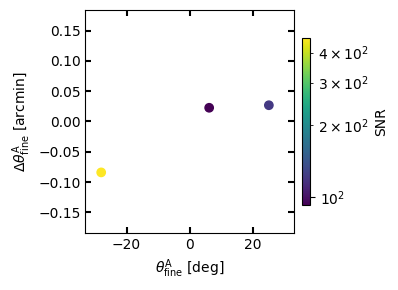

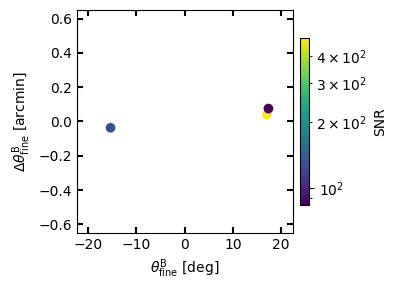

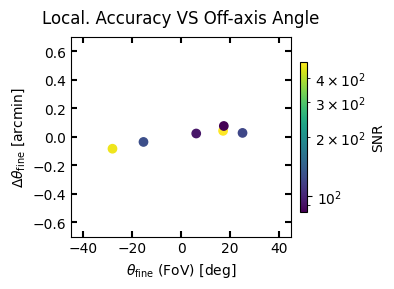

In [31]:
thetax_A, thetax_B = map(np.array, (logA.log['angle_x'], logB.log['angle_x']))


crdres_fine_A = np.array(data_camA['DthetaX'])
offaxis_fine_A = thetax_A - crdres_fine_A
snrvals_A = np.array(data_camA['SNR'])

show_OptimRes_vs_offaxis(
    offaxis=offaxis_fine_A,
    residues=crdres_fine_A,
    snrvals=snrvals_A,
    xlabel='$\\theta_{\\text{fine}}^{\\text{A}}$ [deg]',
    ylabel='$\\Delta\\theta_{\\text{fine}}^{\\text{A}}$ [arcmin]',
    # save_to=f'{OUT_RESULTS_PATH}/coordsRes_vs_offaxis_camA.pdf',
    figsize=(4.0, 3.0),
    xlims=get_symlimits(offaxis_fine_A, offset=5),
    ylims=get_symlimits(crdres_fine_A, offset=0.1),
)


crdres_fine_B = np.array(data_camB['DthetaX'])
offaxis_fine_B = thetax_B - crdres_fine_B
snrvals_B = np.array(data_camB['SNR'])

show_OptimRes_vs_offaxis(
    offaxis=offaxis_fine_B,
    residues=crdres_fine_B,
    snrvals=snrvals_B,
    xlabel='$\\theta_{\\text{fine}}^{\\text{B}}$ [deg]',
    ylabel='$\\Delta\\theta_{\\text{fine}}^{\\text{B}}$ [arcmin]',
    # save_to=f'{OUT_RESULTS_PATH}/coordsRes_vs_offaxis_camB.pdf',
    figsize=(4.0, 3.0),
    xlims=get_symlimits(offaxis_fine_B, offset=5),
    ylims=(-0.65, 0.65), #get_symlimits(crdres_fine_B, offset=0.1),
)

# all from CAM1A and CAM1B
res_cat = np.concat([crdres_fine_A, crdres_fine_B])
show_OptimRes_vs_offaxis(
    offaxis=np.concat([offaxis_fine_A, offaxis_fine_B]),
    residues=res_cat,
    snrvals=np.concat([snrvals_A, snrvals_B]),
    xlabel='$\\theta_{\\text{fine}}$ (FoV) [deg]',
    ylabel='$\\Delta\\theta_{\\text{fine}}$ [arcmin]',
    title='Local. Accuracy VS Off-axis Angle',
    # save_to=f'{OUT_RESULTS_PATH}/coordsRes_vs_offaxis_cams.pdf',
    figsize=(4.0, 3.0),
    xlims=(-45.0, 45.0),  # get_symlimits(offaxis_fine_B, offset=5),
    ylims=(-0.7, 0.7), # get_symlimits(res_cat, offset=0.1),
)

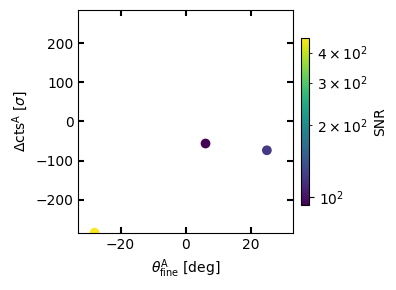

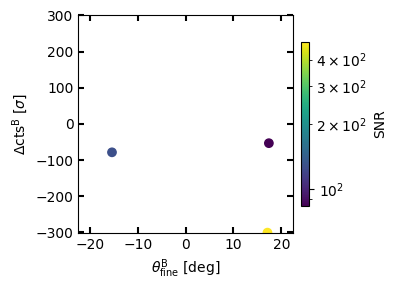

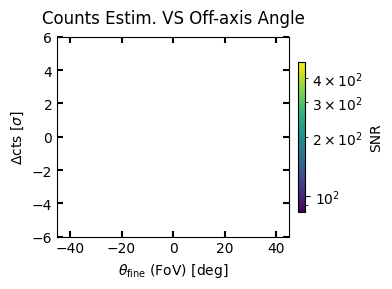

In [32]:
ctsres_A, ctsres_B = map(np.array, (data_camA['Dcts'], data_camB['Dcts']))

show_OptimRes_vs_offaxis(
    offaxis=offaxis_fine_A,
    residues=ctsres_A,
    snrvals=snrvals_A,
    xlabel='$\\theta_{\\text{fine}}^{\\text{A}}$ [deg]',
    ylabel='$\\Delta{\\text{cts}}^{\\text{A}}$ [$\\sigma$]',
    # save_to=f'{OUT_RESULTS_PATH}/ctsRes_vs_offaxis_camA.pdf',
    figsize=(4.0, 3.0),
    xlims=get_symlimits(offaxis_fine_A, offset=5),
    ylims=get_symlimits(ctsres_A, offset=1),
)

show_OptimRes_vs_offaxis(
    offaxis=offaxis_fine_B,
    residues=ctsres_B,
    snrvals=snrvals_B,
    xlabel='$\\theta_{\\text{fine}}^{\\text{B}}$ [deg]',
    ylabel='$\\Delta{\\text{cts}}^{\\text{B}}$ [$\\sigma$]',
    # save_to=f'{OUT_RESULTS_PATH}/ctsRes_vs_offaxis_camB.pdf',
    figsize=(4.0, 3.0),
    xlims=get_symlimits(offaxis_fine_B, offset=5),
    ylims=get_symlimits(ctsres_B, offset=1),
)

# all from CAM1A and CAM1B
res_cat = np.concat([ctsres_A, ctsres_B])
show_OptimRes_vs_offaxis(
    offaxis=np.concat([offaxis_fine_A, offaxis_fine_B]),
    residues=res_cat,
    snrvals=np.concat([snrvals_A, snrvals_B]),
    xlabel='$\\theta_{\\text{fine}}$ (FoV) [deg]',
    ylabel='$\\Delta{\\text{cts}}$ [$\\sigma$]',
    title='Counts Estim. VS Off-axis Angle',
    # save_to=f'{OUT_RESULTS_PATH}/ctsRes_vs_offaxis_cams.pdf',
    figsize=(4.0, 3.0),
    xlims=(-45, 45),  # get_symlimits(offaxis_fine_B, offset=5),
    ylims=(-6, 6), # get_symlimits(crdres_fine_B, offset=0.1),
)

### <center>**LEM-X Unit Point-Source Location Accuracy**<center>

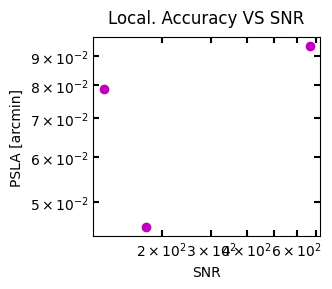

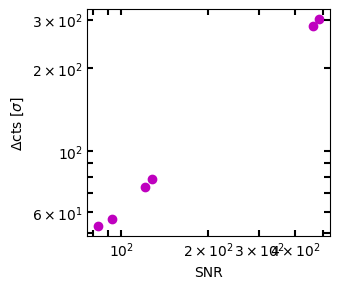

In [33]:
from typing import Optional

def show_psla_vs_snr(
    coord_res: NDArray,
    snrvals: NDArray,
    xlabel: str,
    ylabel: str,
    title: str | None = None,
    save_to: str | Path | None = None,
    save_options: dict[str, Any] | None = None,
    xlims: Optional[tuple[float, float]] = (None, None),
    ylims: Optional[tuple[float, float]] = (None, None),
    **fig_kws,
    ) -> None:
    """Plots the coordinates residues vs off-axis angle."""
    fig, ax = plt.subplots(1, 1, tight_layout=True, **fig_kws)
    ax.scatter(snrvals, coord_res, c='m')
    
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(xlims); ax.set_ylim(ylims)
    ax.set_title(title or '', pad=10)
    ax.set_xlabel(xlabel=xlabel); ax.set_ylabel(ylabel=ylabel)
    ax.xaxis.set_ticks_position('both'); ax.yaxis.set_ticks_position('both')
    ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    plt.show()
    return


# Unit module
cmn_df = unit_data.dropna()
show_psla_vs_snr(
    coord_res=np.sqrt(cmn_df['DthetaX_A'] ** 2 + cmn_df['DthetaX_B'] ** 2),
    snrvals=cmn_df['SNR'],
    # coord_res=np.concat([np.abs(crdres_fine_A), np.abs(crdres_fine_B)]),
    # snrvals=np.concat([snrvals_A, snrvals_B]),
    xlabel='SNR',
    ylabel='PSLA [arcmin]',
    title='Local. Accuracy VS SNR',
    # ylabel='$\\Delta\\theta_{\\text{fine}}$ [arcmin]',
    # save_to=f'{OUT_RESULTS_PATH}/psla_vs_snr_{'smoothed_' if 'smoothed' in RUN_ID else ''}{DATASET}_{E_min}-{E_max}keV_Unit.pdf',
    figsize=(3.4, 3.0),
)

show_psla_vs_snr(
    coord_res=np.concat([np.abs(ctsres_A), np.abs(ctsres_B)]),
    snrvals=np.concat([snrvals_A, snrvals_B]),
    xlabel='SNR',
    ylabel='$\\Delta{\\text{cts}}$ [$\\sigma$]',
    # save_to=f'{OUT_RESULTS_PATH}/dcts_vs_snr_{'smoothed_' if 'smoothed' in RUN_ID else ''}{DATASET}_{E_min}-{E_max}keV_Unit.pdf',
    figsize=(3.5, 3.0),
)

In [34]:
from scipy.optimize import curve_fit

def print_fitres(popt: NDArray, pcov: NDArray, pnames: Optional[tuple[str, ...]] = None) -> NDArray:
    errs = np.sqrt(np.diag(pcov))
    pnames_ = pnames if pnames is not None else [f'p[{idx}]' for idx in range(len(popt))]
    print('Optimised Params:')
    for idx, p in enumerate(popt):
        print(f'  * {pnames_[idx]}: {float(p)} +/- {float(errs[idx])}')
    return


def th_log_psla(x: NDArray, a: float, b: float) -> NDArray:
    return a * x + b


# let's fit the PSLA
y_obs = np.log(np.sqrt(cmn_df['DthetaX_A'] ** 2 + cmn_df['DthetaX_B'] ** 2))[1:]
x = np.log(cmn_df['SNR'])[1:]

popt, pcov = curve_fit(th_log_psla, xdata=x, ydata=y_obs, p0=[-1.0, 0.0])

print_fitres(popt, pcov, pnames=['a', 'b'])

# In 2-50 keV:
#    Optimised Params:
#      * a: -0.537146380389814 +/- 0.20798810369485818
#      * b: 0.2701645365243672 +/- 0.701012456007043

# In 2-6 keV:
#    Optimised Params:
#      * a: -0.9848224727167197 +/- 0.31382676407976173
#      * b: 1.3119988174110335 +/- 1.0353763910969176

Optimised Params:
  * a: -1.614584958746434 +/- inf
  * b: 5.250328764402682 +/- inf


/tmp/ipykernel_6588/1274282229.py:20: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(th_log_psla, xdata=x, ydata=y_obs, p0=[-1.0, 0.0])


In [35]:
def th_psla(x: NDArray, gamma: float, a: float) -> NDArray:
    return a * np.pow(x, gamma)


# let's fit the PSLA
# y_obs = np.concat([np.abs(np.nan_to_num(crdres_fine_A)), np.abs(np.nan_to_num(crdres_fine_B))])
# x = np.concat([snrvals_A, snrvals_B])
y_obs = np.sqrt(cmn_df['DthetaX_A'] ** 2 + cmn_df['DthetaX_B'] ** 2)[1:]
x = cmn_df['SNR'][1:]

popt, pcov = curve_fit(th_psla, xdata=x, ydata=y_obs, p0=[-1.0, 1.0])

print_fitres(popt, pcov)

# In 2-50 keV:
#    Optimised Params:
#      * p[0]: -0.5498519119117626 +/- 0.1949437048958333
#      * p[1]: 1.6040283773903692 +/- 0.8569522028615255

# In 2-6 keV:
#    Optimised Params:
#      * p[0]: -0.6995024175027565 +/- 0.24775988672258584
#      * p[1]: 1.9320150262831546 +/- 1.2992800762653902

Optimised Params:
  * p[0]: -1.6145849587464363 +/- inf
  * p[1]: 190.62893016395824 +/- inf


/tmp/ipykernel_6588/2174031926.py:11: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(th_psla, xdata=x, ydata=y_obs, p0=[-1.0, 1.0])


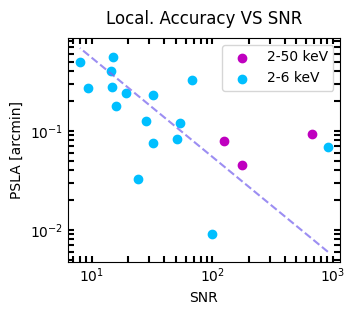

In [36]:
####### NOTE: TEMPORARY PECIONATA TO AVOID WRITING A NEW SCRIPT

def show_psla_vs_snr_across_runs(
    coord_res: list[NDArray],
    snrvals: list[NDArray],
    xlabel: str,
    ylabel: str,
    title: str | None = None,
    save_to: str | Path | None = None,
    colors: Optional[list[str]] = None,
    labels: Optional[list[str]] = None,
    save_options: dict[str, Any] | None = None,
    xlims: Optional[tuple[float, float]] = (None, None),
    ylims: Optional[tuple[float, float]] = (None, None),
    show_thmodel: bool = True,
    **fig_kws,
    ) -> None:
    """Plots the coordinates residues vs off-axis angle."""
    coord_res_, snrvals_ = map(lambda x: x if isinstance(x, list) else [x], (coord_res, snrvals))
    colors_, labels_ = map(lambda x: x if x is not None else [None] * len(coord_res_), (colors, labels))

    fig, ax = plt.subplots(1, 1, tight_layout=True, **fig_kws)

    for snr_arr, coord_arr, c, lbl in zip(snrvals_, coord_res_, colors_, labels_):
        ax.scatter(snr_arr, coord_arr, c=c, label=lbl)

    if show_thmodel:
        ax.plot(snr_arr, np.exp(1.7) * np.pow(snr_arr, -1), linestyle='--', color='MediumSlateBlue', alpha=0.75)
    
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(xlims); ax.set_ylim(ylims)
    ax.set_title(title or '', pad=10)
    ax.set_xlabel(xlabel=xlabel); ax.set_ylabel(ylabel=ylabel)
    ax.xaxis.set_ticks_position('both'); ax.yaxis.set_ticks_position('both')
    ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)
    ax.legend(loc='best')

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    plt.show()
    return


psla_2_6keV = np.array(
    [
        0.068218, 0.008978, 0.323649, 0.119855, 0.082653, 0.232550, 0.074653, 0.127241,
        0.032565, 0.244208, 0.178758, 0.554783, 0.277190, 0.405626, 0.269161, 0.497989
    ],
)
snr_2_6keV = np.array(
    [
        911.863318, 99.928454, 68.019359, 54.127902, 51.343326, 32.311783, 32.204468, 28.239116,
        24.228311, 19.345532, 15.933737, 15.022418, 14.635483, 14.350968, 9.305726, 7.974093
    ],
)


show_psla_vs_snr_across_runs(
    coord_res=[np.sqrt(cmn_df['DthetaX_A'] ** 2 + cmn_df['DthetaX_B'] ** 2), psla_2_6keV],
    snrvals=[cmn_df['SNR'], snr_2_6keV],
    xlabel='SNR',
    ylabel='PSLA [arcmin]',
    title='Local. Accuracy VS SNR',
    colors=['m', 'DeepSkyBlue'],
    labels=['2-50 keV', '2-6 keV'],
    # save_to=f'{OUT_RESULTS_PATH}/psla_vs_snr_{'smoothed_' if 'smoothed' in RUN_ID else ''}{DATASET}_{E_min}-{E_max}keV_Unit_RUNCFR.pdf',
    figsize=(3.4 + 0.25, 3.0 + 0.25),
)